# 02 — From text files to a fine-tuning dataset

**Chapter 3** · suggested time: 30 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_3/02_dialogue_data.ipynb)

![Chapter 3 roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_3/figures/00_roadmap.png)

In chapter 2, preparing the data took one line: `data = torch.tensor(encode(text))`. For supervised fine-tuning, we need to build **examples** `(prompt, response)`. This is the most important step of the chapter: **the decision that matters most is made before the first `backward()`**, in the way we build the examples.

**By the end of this notebook you will be able to:**
1. inspect a raw corpus and spot its defects;
2. split the three corpora into **lines of dialogue** (speaker, text) grouped by scene or dialogue;
3. make a **group-wise** split, and measure the **leakage** of a random split;
4. build conversational examples and put them in Mistral's *chat* format;
5. choose `max_length` from the **distribution of lengths** in tokens;
6. export the files `data/<corpus>_train.jsonl` and `data/<corpus>_val.jsonl` used on Colab.

In [1]:
# Setup. On Colab: we fetch the course repository (data + shared modules).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_3
sys.path.insert(0, "../chapter_2")   # minigpt.py from chapter 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm warning
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # finetune.py, next to this notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import json, statistics
from collections import Counter
import numpy as np
from transformers import AutoTokenizer

CORPORA = ["kaamelott", "plato", "shakespeare"]

PyTorch 2.15.0+cu132


## 1. Look at the raw data first

The three files do **not have the same format**:

| Corpus | Format | Natural groups |
|---|---|---|
| Kaamelott | one row `NAME: line`, a blank row between two scenes | **scenes** |
| Plato | `NAME:` on one row, the line below it, a blank row between lines | **dialogues** (`=== PLA_Gorgias ===`) |
| Shakespeare | same format as Plato | no separator between plays: we will make **blocks of 40 lines** |

Let's look for defects: empty lines, export artifacts, names without text.

In [2]:
raw = {name: ft.load_text(name) for name in CORPORA}

print("Kaamelott — suspicious rows:")
for row in raw["kaamelott"].split("\n"):
    name, _, said = row.partition(":")
    if row and (not said.strip() or '""' in said):
        print("   ", repr(row[:110]))

print("\nShakespeare — a character name without a line:")
i = raw["shakespeare"].index("TITUS:\n\nCOMINIUS")
print(repr(raw["shakespeare"][i - 40:i + 30]))

print("\nPlato — length of the lines (characters):")
lengths = [len(l.text) for g in ft.read_dialogues("plato", cleaning=False) for l in g]
print(f"   median {statistics.median(lengths):.0f}, max {max(lengths)}, > 600 characters: {sum(n > 600 for n in lengths)}")

Kaamelott — suspicious rows:
    'LEODAGAN: '
    'PERCEVAL: "Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague'

Shakespeare — a character name without a line:
' know,\nOur greatest friends attend us.\n\nTITUS:\n\nCOMINIUS:\nNoble Marciu'

Plato — length of the lines (characters):
   median 95, max 2000, > 600 characters: 1806


Three typical defects of a real corpus:
- **empty line** (`LEODAGAN: `: a stage direction was removed during extraction);
- **CSV artifact**: `"Par exemple, Sire, ... ""Bougez pas"" ..."` — the text was exported through a spreadsheet that doubled the quotes;
- multi-paragraph **monologues** in Plato: too long to be a "next line".

## 2. Clean and split into lines

`ft.clean` applies: Unicode normalization (NFC), removal of leftover HTML, repair of CSV quotes, multiple spaces. Line breaks **inside** a line of dialogue are kept (Shakespeare's verse).

In [3]:
before = [l.partition(": ")[2] for l in raw["kaamelott"].split("\n") if '""' in l][0]
print("before:", before[:120])
print("after :", ft.clean(before)[:120])

before: "Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague sous le cou et on t
after : Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague sous le cou et on tr


corpus         groups      lines     speakers      chars/line (median)
kaamelott           7         55            6                       44
plato              45     11,179           39                       95
shakespeare       178      7,097          298                       75


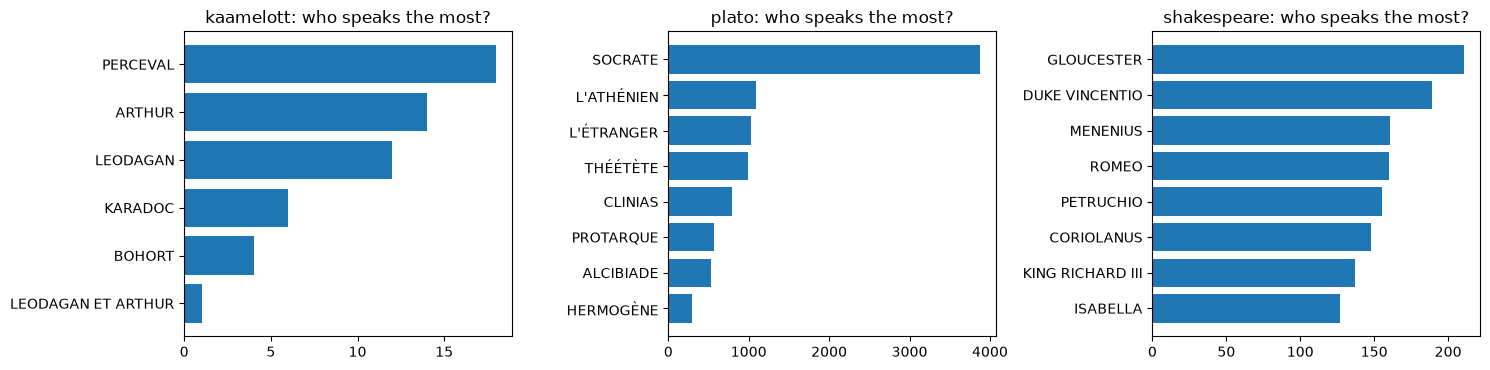

In [4]:
groups = {name: ft.read_dialogues(name) for name in CORPORA}

print(f"{'corpus':12s} {'groups':>8s} {'lines':>10s} {'speakers':>12s} {'chars/line (median)':>24s}")
for name, gs in groups.items():
    lines = [l for g in gs for l in g]
    print(f"{name:12s} {len(gs):8d} {len(lines):10,} {len({l.speaker for l in lines}):12,} {statistics.median(len(l.text) for l in lines):24.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, gs) in zip(axes, groups.items()):
    top = Counter(l.speaker for g in gs for l in g).most_common(8)
    ax.barh([p for p, _ in top][::-1], [n for _, n in top][::-1])
    ax.set_title(f"{name}: who speaks the most?")
plt.tight_layout(); plt.show()

**Kaamelott is tiny**: 7 scenes, about fifty lines. It is a deliberately short excerpt (the same file as in chapter 2). It is enough to **see** a fine-tuning work — and to see a model memorize. For a real project, the series' full Kaggle dataset (> 30,000 lines, see the assignment) would be needed.

Plato is dominated by **Socrates** (and the "Athenian" of the *Laws*): a fine-tuned model will tend to make Socrates speak. This is a **bias of the dataset**, not of the model.

---
## 3. The split: by group, never by line

In chapter 2, we cut the text **in order** (90% / 10%) so that validation contained text never seen. Here, each example contains **the 3 previous lines** as context. If we draw the examples at random, the line to predict in validation appears… in the **context** of a neighboring training example. Let's measure it.

In [5]:
def leak_rate(train, val):
    """Fraction of validation responses found verbatim in a training prompt."""
    contexts = "\n".join(e["prompt"][0]["content"] for e in train)
    return np.mean([e["completion"][0]["content"] in contexts for e in val])

for name in CORPORA:
    everything = ft.build_examples(groups[name], name)
    shuffled = everything[:]
    random.Random(0).shuffle(shuffled)
    n_val = len(shuffled) // 10
    random_leak = leak_rate(shuffled[n_val:], shuffled[:n_val])

    g_train, g_val = ft.split_by_group(groups[name], val_frac=0.2 if name == "kaamelott" else 0.1)
    group_leak = leak_rate(ft.build_examples(g_train, name), ft.build_examples(g_val, name))
    print(f"{name:12s} random split: {random_leak:6.1%} leakage | group-wise split: {group_leak:5.1%}")

kaamelott    random split: 100.0% leakage | group-wise split:  0.0%


plato        random split:  96.4% leakage | group-wise split:  8.2%


shakespeare  random split:  95.4% leakage | group-wise split:  0.2%


With a random split, **almost all** validation responses were seen during training (inside a context). The validation loss would be excellent… and would measure nothing. The **group-wise** split (scene, dialogue, block) reserves **whole** scenes for validation: we measure the ability to continue an **unseen** scene.

What remains with the group-wise split (8% for Plato, almost nothing elsewhere) comes from lines **that repeat** in the corpus ("Oui.", "Certainement.", *Yes., Certainly.*…): they legitimately appear in several dialogues.

For Kaamelott, we reserve 20% (one or two scenes): with 10%, validation would contain only a handful of lines.

---
## 4. Build the examples

`ft.build_examples` turns each line (except the first of a group) into an example:
- **prompt**: the instruction + the `k = 3` previous lines, in the format `NAME: text`;
- **response**: `NAME: line`. So the model must also choose **who speaks**.

Two length safeguards: a context line that is too long is **truncated from the start** (`… ` + the end, the most useful part to follow on from), and a response longer than 600 characters is dropped (we are not learning to write two-page monologues).

In [6]:
VAL_FRAC = {"kaamelott": 0.2, "plato": 0.1, "shakespeare": 0.1}
datasets = {}
for name in CORPORA:
    g_train, g_val = ft.split_by_group(groups[name], val_frac=VAL_FRAC[name], seed=42)
    train = ft.deduplicate(ft.build_examples(g_train, name, k=3))
    val = ft.deduplicate(ft.build_examples(g_val, name, k=3))
    datasets[name] = (train, val)
    print(f"{name:12s} train: {len(train):5,} examples | val: {len(val):4,} examples "
          f"| val responses identical to a train response: {len(ft.leaks(train, val))}")

example = datasets["plato"][0][123]
print("\n--- a Plato example ---")
print(json.dumps({k: example[k] for k in ("prompt", "completion")}, ensure_ascii=False, indent=1))

kaamelott    train:    38 examples | val:   10 examples | val responses identical to a train response: 0
plato        train: 8,335 examples | val: 1,013 examples | val responses identical to a train response: 55
shakespeare  train: 6,013 examples | val:  665 examples | val responses identical to a train response: 0

--- a Plato example ---
{
 "prompt": [
  {
   "role": "user",
   "content": "Continue ce dialogue de Platon (traduction de Victor Cousin) avec la réplique suivante.\n\nHERMOGÈNE: Assurément.\nSOCRATE: Peux-tu m'en dire autant au sujet du nom ? Si c'est un instrument, qu'en faisons-nous quand nous nommons ?\nHERMOGÈNE: C'est ce que je ne puis dire."
  }
 ],
 "completion": [
  {
   "role": "assistant",
   "content": "SOCRATE: N'est-ce pas que nous nous apprenons quelque chose les uns aux autres, et que nous démêlons les manières d'être des divers objets ?"
  }
 ]
}


In [7]:
for e in ft.leaks(*datasets["plato"])[:8]:
    print(repr(e["completion"][0]["content"]))

'CLINIAS: Sans doute.'
'CLINIAS: Nécessairement.'
'CLINIAS: Il y a toute apparence.'
'CLINIAS: Tu as raison.'
'CLINIAS: Tu as parfaitement raison.'
'CLINIAS: Cela est certain.'
'CLINIAS: Rien de plus vrai.'
'CLINIAS: Cela est vraisemblable.'


The remaining Plato "leaks" are **set phrases** of the Socratic dialogue. They are legitimate (the model must learn that the interlocutor often agrees!), but you need to know they exist: they make validation a bit optimistic. This is not the case for **near-duplicates** (the same line with different punctuation), which an n-gram or MinHash search could find — an exercise in the assignment.

---
## 5. Switch to Mistral's format and count the tokens

The model does not see a Python dictionary but a **string** formatted by the *chat template* (notebook 01, §4). Let's measure the length of each example **in tokens**, to choose `max_length` — the maximum length of a sequence during training.

In [8]:
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print(tokenizer.apply_chat_template(example["prompt"] + example["completion"], tokenize=False))

def n_tokens(e):
    return len(tokenizer.apply_chat_template(e["prompt"] + e["completion"])["input_ids"])

lengths = {name: np.array([n_tokens(e) for e in train]) for name, (train, val) in datasets.items()}

<s>[INST] Continue ce dialogue de Platon (traduction de Victor Cousin) avec la réplique suivante.

HERMOGÈNE: Assurément.
SOCRATE: Peux-tu m'en dire autant au sujet du nom ? Si c'est un instrument, qu'en faisons-nous quand nous nommons ?
HERMOGÈNE: C'est ce que je ne puis dire.[/INST] SOCRATE: N'est-ce pas que nous nous apprenons quelque chose les uns aux autres, et que nous démêlons les manières d'être des divers objets ?</s>


corpus          p50    p90    p95    p99    max   > 512 tokens
kaamelott       131    155    160    181    192     0.0%
plato           185    342    401    530    749     1.3%
shakespeare     162    303    348    430    579     0.1%


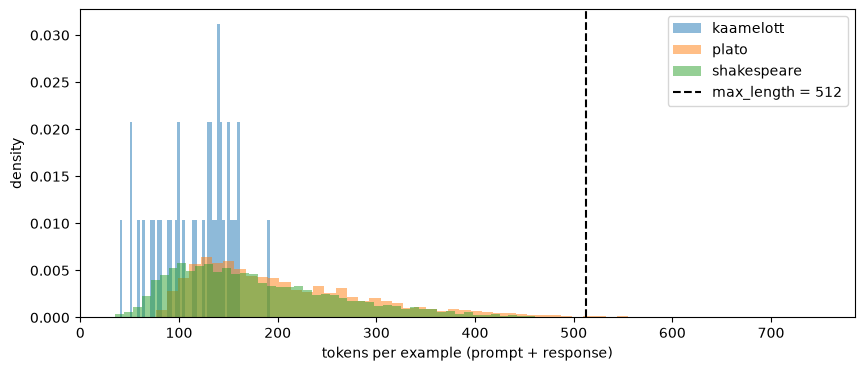

In [9]:
print(f"{'corpus':12s} {'p50':>6s} {'p90':>6s} {'p95':>6s} {'p99':>6s} {'max':>6s}   > 512 tokens")
for name, L in lengths.items():
    p = np.percentile(L, [50, 90, 95, 99])
    print(f"{name:12s} " + " ".join(f"{x:6.0f}" for x in p) + f" {L.max():6d}   {np.mean(L > 512):6.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
for name, L in lengths.items():
    ax.hist(L, bins=60, alpha=0.5, density=True, label=name)
ax.axvline(512, color="black", ls="--", label="max_length = 512")
ax.set_xlabel("tokens per example (prompt + response)"); ax.set_ylabel("density"); ax.legend()
plt.show()

**Choice: `max_length = 512`.** It covers almost all examples (we measure, we do not pick "2048 out of habit"). The rare longer examples will be **truncated** at the end: they lose the end of their response, which is acceptable for 1% of the data.

Why not take 32,768, Mistral's window? The memory of the **activations** grows with the sequence length (notebook 04), and we would pay for *padding*. The right value comes from the distribution of the data, not from the model's spec sheet.

### How many training tokens?

The cost of a fine-tuning is proportional to the **number of tokens processed** (notebook 05):

In [10]:
for name, L in lengths.items():
    print(f"{name:12s} {len(L):6,} examples, {L.sum():>10,} tokens per epoch (mean {L.mean():.0f} tokens/example)")

kaamelott        38 examples,      4,433 tokens per epoch (mean 117 tokens/example)
plato         8,335 examples,  1,749,733 tokens per epoch (mean 210 tokens/example)
shakespeare   6,013 examples,  1,084,945 tokens per epoch (mean 180 tokens/example)


On a Colab T4 GPU, a QLoRA of Mistral 7B processes on the order of a few hundred tokens per second: a full epoch of Plato or Shakespeare would take several hours. In notebook 05, we will therefore train on a **subsample** (a few hundred to a thousand examples): the goal in class is to see **the complete pipeline**, not to get the best model.

---
## 6. Export

One example per line, in JSON format (*JSON Lines*). The `prompt` / `completion` fields are those expected by the TRL library; `speaker` and `group` are used for analysis. These files are versioned in the repository: notebook 05, on Colab, downloads them directly.

In [11]:
from pathlib import Path
for name, (train, val) in datasets.items():
    ft.save_jsonl(train, f"data/{name}_train.jsonl")
    ft.save_jsonl(val, f"data/{name}_val.jsonl")
for f in sorted(Path("data").glob("*.jsonl")):
    print(f"{str(f):32s} {f.stat().st_size / 1e6:6.2f} MB  {sum(1 for _ in f.open()):6,} examples")

reread = ft.load_jsonl("data/kaamelott_val.jsonl")
print("\nRead back:", reread[0]["completion"])

data/kaamelott_train.jsonl         0.02 MB      38 examples
data/kaamelott_val.jsonl           0.01 MB      10 examples
data/plato_train.jsonl             6.40 MB   8,335 examples
data/plato_val.jsonl               1.09 MB   1,013 examples
data/shakespeare_train.jsonl       4.39 MB   6,013 examples
data/shakespeare_val.jsonl         0.48 MB     665 examples

Read back: [{'role': 'assistant', 'content': 'ARTHUR: Ben attendez ! J’vais vous rendre la votre !'}]


## Summary

- A raw corpus is **not** a dataset: extraction defects, empty lines, CSV artifacts, monologues. We **look** before training.
- The split is made **by group** (scene, dialogue): a random split leaks ~100% of the validation responses into the training contexts.
- An SFT example = `prompt` (instruction + context) → `completion` (next line). How these pairs are built **defines the task**.
- `max_length` is chosen from the **distribution of lengths in tokens** (here 512).
- Cost is counted in **tokens**, not in rows.

**Check your understanding**
1. Why are Shakespeare's 40-line blocks a stopgap? What would the ideal group be?
2. What would the validation loss measure if we had made a random split?
3. Why truncate a **context** line from the **start** rather than from the end?
4. The speaker of the response is part of the target (`KARADOC: ...`). What behavior does this teach the model? What would the `"speaker"` mode change?